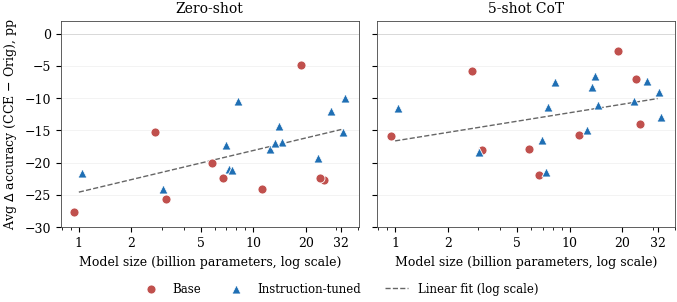

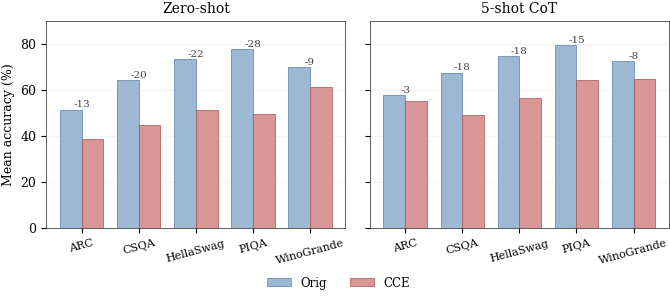

In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

mpl.rcParams.update({
    "font.size": 9,
    "font.family": "serif",
    "axes.linewidth": 0.6,
    "axes.edgecolor": "#444444",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# (family, size_in_B, IT, avg_delta_zero, avg_delta_few)
rows = [
    ("GPT-3",       2.7, False, -15.3,  -5.8),
    ("GPT-3",       6.0, False, -20.0, -17.9),
    ("GPT-3",      20.0, False,  -4.8,  -2.7),
    ("LLaMA-3.2",   1.0, False, -27.7, -15.9),
    ("LLaMA-3.2",   1.0, True,  -21.6, -11.6),
    ("LLaMA-3.2",   3.0, False, -25.7, -18.0),
    ("LLaMA-3.2",   3.0, True,  -24.1, -18.3),
    ("Qwen-3",      8.0, True,  -10.4,  -7.5),
    ("Qwen-3",     14.0, True,  -14.3,  -6.6),
    ("Qwen-3",     32.0, True,  -10.0, -13.0),
    ("Phi-4",      14.0, True,  -16.8, -11.1),
    ("Gemma-3",    12.0, False, -24.1, -15.7),
    ("Gemma-3",    12.0, True,  -17.9, -14.9),
    ("Gemma-3",    27.0, False, -22.7, -14.0),
    ("Gemma-3",    27.0, True,  -12.0,  -7.4),
    ("Mistral",     7.0, False, -22.4, -21.9),
    ("Mistral",     7.0, True,  -21.0, -21.5),
    ("Mistral",    24.0, False, -22.4,  -7.1),
    ("Mistral",    24.0, True,  -19.3, -10.4),
    ("DeepSeek-R1", 7.0, True,  -17.2, -16.5),
    ("DeepSeek-R1", 8.0, True,  -21.1, -11.3),
    ("DeepSeek-R1",14.0, True,  -16.9,  -8.2),
    ("DeepSeek-R1",32.0, True,  -15.3,  -9.1),
]

C_BASE, C_IT = "#C0504D", "#1F6FB4"

def scatter_panel(ax, dz_idx, title):
    sizes  = np.array([r[1] for r in rows])
    its    = np.array([r[2] for r in rows])
    deltas = np.array([r[3 + dz_idx] for r in rows])
    rng = np.random.default_rng(0)
    x = sizes * (1.0 + (rng.random(len(sizes)) - 0.5) * 0.12)  # jitter

    for mask, color, lab, marker in [
        (~its, C_BASE, "Base", "o"),
        (its,  C_IT,   "Instruction-tuned", "^"),
    ]:
        ax.scatter(x[mask], deltas[mask], c=color, marker=marker, s=42,
                   edgecolors="white", linewidths=0.6, label=lab, zorder=3)

    lx = np.log10(sizes)
    coef = np.polyfit(lx, deltas, 1)
    xs = np.linspace(lx.min(), lx.max(), 50)
    ax.plot(10**xs, np.polyval(coef, xs), color="#666666", lw=1.0,
            ls="--", zorder=2, label="Linear fit (log scale)")

    ax.axhline(0, color="#999999", lw=0.6, zorder=1)
    ax.set_xscale("log")
    ax.set_xticks([1, 2, 5, 10, 20, 32])
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.set_xlabel("Model size (billion parameters, log scale)")
    ax.set_ylabel(r"Avg $\Delta$ accuracy (CCE $-$ Orig), pp")
    ax.set_title(title, fontsize=10)
    ax.grid(True, which="both", axis="y", color="#EEEEEE", lw=0.5, zorder=0)
    ax.set_ylim(-30, 2)

fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
scatter_panel(axes[0], 0, "Zero-shot")
scatter_panel(axes[1], 1, "5-shot CoT")
axes[1].set_ylabel("")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.06), fontsize=8.5)
fig.tight_layout(rect=[0, 0.02, 1, 1])
fig.savefig("fig_robustness_scale.pdf")

# ---- Grouped bar: mean Orig vs CCE per dataset (exact, across all 23 models) ----
ds = ["ARC", "CSQA", "HellaSwag", "PIQA", "WinoGrande"]
zero_orig = [51.4, 64.2, 73.5, 77.8, 70.0]
zero_cce  = [38.4, 44.6, 51.3, 49.3, 61.4]
few_orig  = [57.7, 67.5, 74.7, 79.4, 72.6]
few_cce   = [55.1, 49.1, 56.6, 64.1, 64.6]

def bar_panel(ax, orig, cce, title):
    x = np.arange(len(ds)); w = 0.38
    ax.bar(x - w/2, orig, w, color="#9DB8D2", label="Orig", zorder=3,
           edgecolor="#5A7FA6", linewidth=0.5)
    ax.bar(x + w/2, cce,  w, color="#D99694", label="CCE", zorder=3,
           edgecolor="#A8504D", linewidth=0.5)
    for xi, (o, c) in enumerate(zip(orig, cce)):
        ax.annotate(f"-{o-c:.0f}", (xi, max(o, c) + 1.2), ha="center",
                    fontsize=7.5, color="#444444")
    ax.set_xticks(x); ax.set_xticklabels(ds, fontsize=8, rotation=15)
    ax.set_ylabel("Mean accuracy (%)")
    ax.set_title(title, fontsize=10); ax.set_ylim(0, 90)
    ax.grid(True, axis="y", color="#EEEEEE", lw=0.5, zorder=0)

fig2, axes2 = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
bar_panel(axes2[0], zero_orig, zero_cce, "Zero-shot")
bar_panel(axes2[1], few_orig, few_cce, "5-shot CoT")
axes2[1].set_ylabel("")
h2, l2 = axes2[0].get_legend_handles_labels()
fig2.legend(h2, l2, loc="lower center", ncol=2, frameon=False,
            bbox_to_anchor=(0.5, -0.04), fontsize=8.5)
fig2.tight_layout(rect=[0, 0.03, 1, 1])
fig2.savefig("fig_dataset_gap.pdf")

\begin{figure}[t]
  \centering
  \includegraphics[width=\columnwidth]{fig_robustness_scale.pdf}
  \caption{Average accuracy change under CCE (Avg $\Delta$ = CCE $-$ Orig,
  in percentage points, averaged over the five datasets) versus model size
  on a log scale, for zero-shot (left) and 5-shot CoT (right). Circles are
  base models, triangles instruction-tuned; the dashed line is a linear fit
  on log-size. Larger models tend to degrade less, but the wide scatter
  shows scale alone does not determine robustness, and instruction-tuned
  models generally lie above base models of comparable size.}
  \label{fig:scale}
\end{figure}

\begin{figure}[t]
  \centering
  \includegraphics[width=\columnwidth]{fig_dataset_gap.pdf}
  \caption{Mean accuracy across all evaluated models under the original
  (Orig) and counterfactual (CCE) settings, per dataset, for zero-shot
  (left) and 5-shot CoT (right). Numbers above each pair give the Orig$-$CCE
  gap in points. The gap is largest on PIQA and HellaSwag and smallest on
  WinoGrande; CoT reduces but does not eliminate it.}
  \label{fig:dataset}
\end{figure}